# Lab 2-06：用標註資料評估 prompt

**目標**：改 prompt 不能靠「感覺比較好」。準備一份有標準答案的工單資料，用同一份測試集比較兩版 prompt 的準確率，
再用混淆矩陣看錯在哪兩類之間。

**你會學到**
- 開發集（dev）與測試集（test）分開：調 prompt 用 dev，報數字用 test
- 準確率、各類別的表現，用 scikit-learn 一行算完
- 混淆矩陣：一眼看出模型把哪一類誤判成哪一類
- 只有 36 題時，兩個準確率的差距有多可信（bootstrap）

**前置**：Lab 2-01（四段結構）。資料在 `data/tickets.csv`（48 張自寫的虛構工單）。

**對應投影片**：「提示詞的四段結構」「少樣本：從示例學格式」「推理模型：定義成功」

![混淆矩陣怎麼讀](images/confusion_matrix.jpg)

*圖：列是標準答案、欄是模型預測。對角線（深色）是答對的；不在對角線上的格子就是錯誤，
例如朱紅那格代表「標準答案是帳務，模型卻說帳號」。看哪幾格最深，就知道 prompt 該補哪一條定義。*

## Step 1：讀標註資料

每張工單有一個標準類別（網路、資料庫、帳號、帳務）。`split` 欄把資料分成兩份：
- **dev（12 張）**：寫 prompt 時可以看、可以拿來當少樣本範例
- **test（36 張）**：只用來打分數，寫 prompt 時不准看

如果拿 test 的題目去調 prompt，分數會虛高，跟「拿考題練習再考同一份考卷」一樣。

In [1]:
import pandas as pd

df = pd.read_csv("data/tickets.csv")
print(df.groupby(["split", "label"]).size().unstack())
df.head(6)

label  帳務  帳號  網路  資料庫
split                 
dev     3   3   3    3
test    9   9  10    8


,id,split,text,label
0,1,dev,公司內網 VPN 連不上，整個業務部都卡住,網路
1,2,dev,訂單資料表查詢很慢，慢查詢日誌一直跳出同一條 SQL,資料庫
2,3,dev,新進同事登入後台顯示權限不足，看不到報表頁,帳號
3,4,dev,上個月被重複扣款兩次，請協助退款,帳務
4,5,dev,從新加坡連到台北機房的延遲飆到 2 秒，ping 會掉封包,網路
5,6,dev,昨晚的資料庫備份排程失敗，備份檔大小是 0,資料庫


In [2]:
LABELS = ["網路", "資料庫", "帳號", "帳務"]
dev = df[df.split == "dev"].reset_index(drop=True)
test = df[df.split == "test"].reset_index(drop=True)
print(f"dev {len(dev)} 張、test {len(test)} 張")

dev 12 張、test 36 張


## Step 2：版本 A——最簡單的分類 prompt

In [3]:
from course_utils.llm import chat


def prompt_a(text: str) -> list[dict]:
    return [{"role": "user", "content": f"這張工單屬於哪一類？網路、資料庫、帳號、帳務。只回答類別。\n工單：{text}"}]


def parse_label(output: str) -> str:
    """取輸出裡最早出現的類別名稱；都沒有就算無法解析。"""
    hits = [(output.find(lab), lab) for lab in LABELS if lab in output]
    return min(hits)[1] if hits else "無法解析"


sample = test.text[0]
out = chat(prompt_a(sample))
print(sample, "→", repr(out), "→", parse_label(out))

官網在部分地區打不開，查了是 DNS 解析失敗 → '網路' → 網路


## Step 3：在 test 上跑版本 A

36 次呼叫，溫度 0，約 30 秒到 1 分鐘。

In [4]:
import time

t0 = time.time()
test["pred_a"] = [parse_label(chat(prompt_a(t))) for t in test.text]
print(f"{time.time() - t0:.0f} 秒")
print("版本 A 準確率：", f"{(test.pred_a == test.label).mean():.1%}")

47 秒
版本 A 準確率： 86.1%


## Step 4：版本 B——寫清楚定義、加上範例

先在 dev 上看版本 A 錯在哪（這裡省略那一步，直接給結果）：模型分不清「根因是網路，但出事的是資料庫主機」這類邊界情況，
也常把「帳單畫面」「權限資料表」這種同時沾到兩類的工單分錯。

所以版本 B 照四段結構寫，**約束裡寫明每一類的定義與邊界規則**，再從 dev 挑四張當範例（一類一張）。

In [5]:
DEFINITIONS = """- 網路：連線、延遲、頻寬、DNS、VPN、CDN、憑證、防火牆、機房線路。只要根因是網路，即使出事的是資料庫主機或登入服務，也算網路。
- 資料庫：查詢效能、連線池、複寫、備份還原、資料重複或不一致、資料表空間。
- 帳號：登入、密碼、權限、兩步驟驗證、SSO、API 金鑰、帳號啟用停用。權限資料被改錯也算帳號。
- 帳務：扣款、退款、發票、帳單、方案與價格。帳單畫面上的金額問題也算帳務。"""

SHOTS = dev[dev.id.isin([9, 10, 5, 12])]
EXAMPLES = "\n".join(f"工單：{r.text}\n類別：{r.label}" for r in SHOTS.itertuples())


def prompt_b(text: str) -> list[dict]:
    system = f"""# 角色
你是星帆雲端的工單分流員。

# 任務
把工單分到四個類別之一：網路、資料庫、帳號、帳務。

# 類別定義
{DEFINITIONS}

# 約束
- 看「要處理的根因」分類，不是看工單提到哪個系統
- 只輸出類別名稱，不要解釋

# 示例
{EXAMPLES}"""
    return [{"role": "system", "content": system}, {"role": "user", "content": f"工單：{text}\n類別："}]


print(prompt_b(sample)[0]["content"])

# 角色
你是星帆雲端的工單分流員。

# 任務
把工單分到四個類別之一：網路、資料庫、帳號、帳務。

# 類別定義
- 網路：連線、延遲、頻寬、DNS、VPN、CDN、憑證、防火牆、機房線路。只要根因是網路，即使出事的是資料庫主機或登入服務，也算網路。
- 資料庫：查詢效能、連線池、複寫、備份還原、資料重複或不一致、資料表空間。
- 帳號：登入、密碼、權限、兩步驟驗證、SSO、API 金鑰、帳號啟用停用。權限資料被改錯也算帳號。
- 帳務：扣款、退款、發票、帳單、方案與價格。帳單畫面上的金額問題也算帳務。

# 約束
- 看「要處理的根因」分類，不是看工單提到哪個系統
- 只輸出類別名稱，不要解釋

# 示例
工單：從新加坡連到台北機房的延遲飆到 2 秒，ping 會掉封包
類別：網路
工單：API 回應很慢，查下去發現是一條沒加索引的 SQL 在全表掃描
類別：資料庫
工單：付款完成後帳號被鎖住，顯示異常登入
類別：帳號
工單：升級方案後帳單金額還是舊方案的價格
類別：帳務


In [6]:
t0 = time.time()
test["pred_b"] = [parse_label(chat(prompt_b(t))) for t in test.text]
print(f"{time.time() - t0:.0f} 秒")
print("版本 B 準確率：", f"{(test.pred_b == test.label).mean():.1%}")

14 秒
版本 B 準確率： 94.4%


## Step 5：各類別的表現

整體準確率會把細節蓋掉。`classification_report` 列出每一類的 precision（說是這類的裡面，幾成真的是）、
recall（真的是這類的裡面，抓到幾成）。

In [7]:
from sklearn.metrics import classification_report

for name in ["pred_a", "pred_b"]:
    print(f"=== 版本 {name[-1].upper()}")
    print(classification_report(test.label, test[name], labels=LABELS, zero_division=0, digits=2))

=== 版本 A
              precision    recall  f1-score   support

          網路       0.91      1.00      0.95        10
         資料庫       1.00      0.75      0.86         8
          帳號       0.75      1.00      0.86         9
          帳務       0.86      0.67      0.75         9

    accuracy                           0.86        36
   macro avg       0.88      0.85      0.85        36
weighted avg       0.88      0.86      0.86        36

=== 版本 B
              precision    recall  f1-score   support

          網路       1.00      1.00      1.00        10
         資料庫       1.00      0.88      0.93         8
          帳號       0.82      1.00      0.90         9
          帳務       1.00      0.89      0.94         9

    accuracy                           0.94        36
   macro avg       0.95      0.94      0.94        36
weighted avg       0.95      0.94      0.95        36



## Step 6：混淆矩陣

兩版並排。預測那一軸多一欄「無法解析」，模型沒照格式回答時會落在這裡。

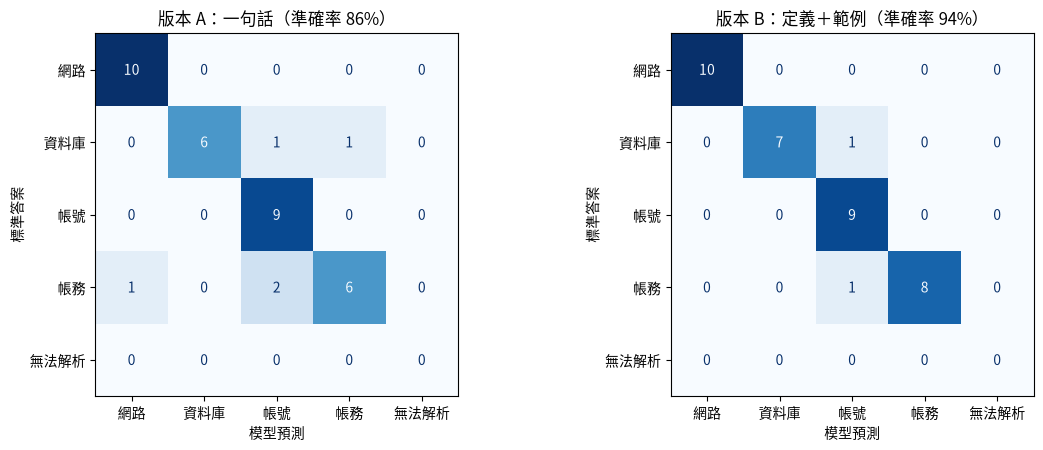

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

from course_utils.viz import setup_cjk

setup_cjk()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, name, title in zip(axes, ["pred_a", "pred_b"], ["版本 A：一句話", "版本 B：定義＋範例"]):
    ConfusionMatrixDisplay.from_predictions(
        test.label, test[name], labels=LABELS + ["無法解析"], ax=ax, cmap="Blues", colorbar=False)
    acc = (test[name] == test.label).mean()
    ax.set_title(f"{title}（準確率 {acc:.0%}）")
    ax.set_xlabel("模型預測")
    ax.set_ylabel("標準答案")
plt.tight_layout()
plt.show()

「無法解析」那一列永遠是 0（標準答案不會是它），只有那一欄有意義。讀圖時找**對角線以外最深的格子**：
那就是下一版 prompt 該補的定義。

## Step 7：哪些題改對了、哪些改錯了

準確率上升，不代表每一題都變好。把兩版結果不同的題目列出來：

In [9]:
changed = test[test.pred_a != test.pred_b]
for r in changed.itertuples():
    mark = "改對" if r.pred_b == r.label else ("改錯" if r.pred_a == r.label else "都錯")
    print(f"[{mark}] {r.text[:30]:32s} 標準={r.label}　A={r.pred_a}　B={r.pred_b}")

[改對] 報表上的營收數字跟資料庫裡算出來的對不起來            標準=資料庫　A=帳務　B=資料庫
[改錯] 同一筆客戶資料在資料表裡出現兩次，主鍵好像沒設好         標準=資料庫　A=資料庫　B=帳號
[改對] 夜間批次匯入資料時發生死結，整批失敗               標準=資料庫　A=帳號　B=資料庫
[改對] 統一編號打錯了，發票需要作廢重開                 標準=帳務　A=帳號　B=帳務
[改對] 海外信用卡付款一直被拒絕                     標準=帳務　A=網路　B=帳務


「改錯」的題目要特別看：新加的規則可能讓原本對的題目被套錯規則。這就是為什麼每次改 prompt 都要重跑**整份**測試集。

## Step 8：36 題的差距可信嗎？

測試集很小，差一兩題準確率就差 3～6%。用 bootstrap 估計：從 36 題中**有放回地**重抽 36 題，算兩版的準確率差，重複 2000 次，
看這個差距的分布。如果分布大部分都在 0 的右邊，才比較有把握說 B 比 A 好。

這段只有幾行，用 numpy 直接寫；這種情況沒必要另外裝統計套件。

B − A 準確率差：+8.5%，95% 區間 [-2.8%, +19.4%]，差距 ≤ 0 的比例 10.2%


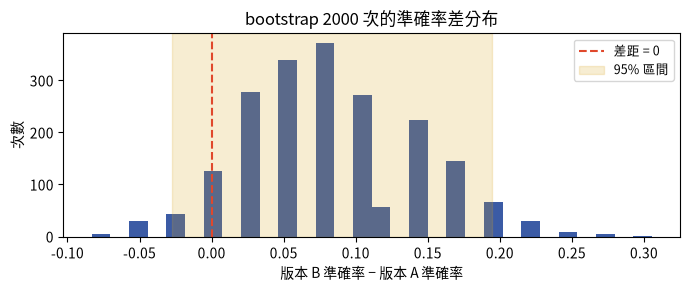

In [10]:
import numpy as np

rng = np.random.default_rng(0)
correct_a = (test.pred_a == test.label).to_numpy()
correct_b = (test.pred_b == test.label).to_numpy()
idx = rng.integers(0, len(test), size=(2000, len(test)))
diffs = correct_b[idx].mean(axis=1) - correct_a[idx].mean(axis=1)
low, high = np.percentile(diffs, [2.5, 97.5])
print(f"B − A 準確率差：{diffs.mean():+.1%}，95% 區間 [{low:+.1%}, {high:+.1%}]，差距 ≤ 0 的比例 {(diffs <= 0).mean():.1%}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(diffs, bins=30, color="#3b5ba5")
ax.axvline(0, color="#e0482c", linestyle="--", label="差距 = 0")
ax.axvspan(low, high, color="#d9a520", alpha=0.2, label="95% 區間")
ax.set_xlabel("版本 B 準確率 − 版本 A 準確率")
ax.set_ylabel("次數")
ax.set_title("bootstrap 2000 次的準確率差分布")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

如果 95% 區間跨過 0，就表示「B 比較好」這個結論在 36 題上還站不住，需要更多標註資料。
這也是模組 8 回歸評估的基礎：固定一份題目，每次改 prompt 都跑一次，看分數有沒有退步。

## 試試看

1. 只保留版本 B 的「類別定義」、拿掉「示例」，重跑 Step 4～6。定義和範例，哪一個貢獻比較大？
2. 看混淆矩陣裡最深的錯誤格子，在 `DEFINITIONS` 補一條規則，重跑。整體準確率有變嗎？有沒有題目「改錯」？
3. 把版本 B 改用 Lab 2-03 的 `parse()` 加上 `Literal["網路", "資料庫", "帳號", "帳務"]`，「無法解析」那一欄還會有數字嗎？

## 小結

- 評估 prompt 要有標註資料，並把 dev 和 test 分開：調整只看 dev，數字只報 test。
- 準確率之外，用分類報告和混淆矩陣看錯在哪兩類之間，再針對那裡補定義；每次改完重跑整份測試集。
- 小資料上的差距要用 bootstrap 看可不可信。模組 2 到這裡結束；模組 3 RAG 要解決另一個問題：模型不知道的知識，怎麼在提問時補給它。